# Level 2 - Task 4: Restaurant Chains

**Objective:**
1. Identify if there are any restaurant chains present in the dataset.
2. Analyze the ratings and popularity of different restaurant chains.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Load dataset
df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"Unique Restaurant Names: {df['Restaurant Name'].nunique()}")

# Check how many names appear more than once
name_counts = df['Restaurant Name'].value_counts()
chains = name_counts[name_counts > 1]

print(f"\n🔗 Restaurants appearing multiple times (potential chains): {len(chains)}")
print(f"Total outlets of these chains: {chains.sum()}")

✅ Dataset loaded!
Total Restaurants: 9551
Unique Restaurant Names: 7446

🔗 Restaurants appearing multiple times (potential chains): 734
Total outlets of these chains: 2839


In [2]:
# Chain = same restaurant name in multiple locations
chain_counts = df['Restaurant Name'].value_counts()

# Filter: names that appear 2+ times
chains = chain_counts[chain_counts >= 2]

print("=" * 70)
print("🔗 TOP 20 RESTAURANT CHAINS (By Number of Outlets)")
print("=" * 70)

for rank, (name, count) in enumerate(chains.head(20).items(), 1):
    print(f"{rank:2d}. {name:45s} → {count} outlets")

🔗 TOP 20 RESTAURANT CHAINS (By Number of Outlets)
 1. Cafe Coffee Day                               → 83 outlets
 2. Domino's Pizza                                → 79 outlets
 3. Subway                                        → 63 outlets
 4. Green Chick Chop                              → 51 outlets
 5. McDonald's                                    → 48 outlets
 6. Keventers                                     → 34 outlets
 7. Pizza Hut                                     → 30 outlets
 8. Giani                                         → 29 outlets
 9. Baskin Robbins                                → 28 outlets
10. Barbeque Nation                               → 26 outlets
11. Giani's                                       → 22 outlets
12. Barista                                       → 22 outlets
13. Dunkin' Donuts                                → 22 outlets
14. Costa Coffee                                  → 20 outlets
15. Pind Balluchi                                 → 20 outlets
16. W

In [3]:
# Detailed stats for each chain
chain_df = df[df['Restaurant Name'].isin(chains.index)].copy()

chain_stats = chain_df.groupby('Restaurant Name').agg(
    outlets=('Restaurant ID', 'count'),
    avg_rating=('Aggregate rating', 'mean'),
    total_votes=('Votes', 'sum'),
    avg_votes=('Votes', 'mean'),
    cities=('City', 'nunique')
).reset_index()

chain_stats = chain_stats.sort_values('outlets', ascending=False)

print("=" * 90)
print("📊 TOP 15 CHAINS - DETAILED ANALYSIS")
print("=" * 90)
print(f"{'Chain Name':<40} {'Outlets':<10} {'Avg Rating':<12} {'Cities':<10} {'Total Votes':<12}")
print("-" * 90)

for _, row in chain_stats.head(15).iterrows():
    print(f"{row['Restaurant Name']:<40} {row['outlets']:<10} {row['avg_rating']:<12.2f} {row['cities']:<10} {row['total_votes']:<12}")
print("=" * 90)

📊 TOP 15 CHAINS - DETAILED ANALYSIS
Chain Name                               Outlets    Avg Rating   Cities     Total Votes 
------------------------------------------------------------------------------------------
Cafe Coffee Day                          83         2.42         5          2428        
Domino's Pizza                           79         2.74         7          6643        
Subway                                   63         2.91         5          6124        
Green Chick Chop                         51         2.67         4          964         
McDonald's                               48         3.34         7          5291        
Keventers                                34         2.87         4          1263        
Pizza Hut                                30         3.32         12         4961        
Giani                                    29         2.69         4          854         
Baskin Robbins                           28         1.86         5      

In [4]:
# Chain = appears 2+ times
# Non-chain = appears only once

chain_names = chains.index.tolist()

df['Is_Chain'] = df['Restaurant Name'].apply(lambda x: 'Chain' if x in chain_names else 'Independent')

comparison = df.groupby('Is_Chain').agg(
    count=('Restaurant ID', 'count'),
    avg_rating=('Aggregate rating', 'mean'),
    avg_votes=('Votes', 'mean'),
    total_votes=('Votes', 'sum')
).round(2)

print("=" * 70)
print("📊 CHAIN VS INDEPENDENT RESTAURANTS")
print("=" * 70)
print(comparison.to_string())
print("=" * 70)

# Percentage
total = len(df)
for idx, row in comparison.iterrows():
    pct = (row['count'] / total) * 100
    print(f"\n{idx}: {row['count']} restaurants ({pct:.2f}%)")
    print(f"   → Avg Rating: {row['avg_rating']}")
    print(f"   → Avg Votes: {row['avg_votes']}")

📊 CHAIN VS INDEPENDENT RESTAURANTS
             count  avg_rating  avg_votes  total_votes
Is_Chain                                              
Chain         2839        2.79     179.87       510664
Independent   6712        2.61     147.20       987981

Chain: 2839.0 restaurants (29.72%)
   → Avg Rating: 2.79
   → Avg Votes: 179.87

Independent: 6712.0 restaurants (70.28%)
   → Avg Rating: 2.61
   → Avg Votes: 147.2


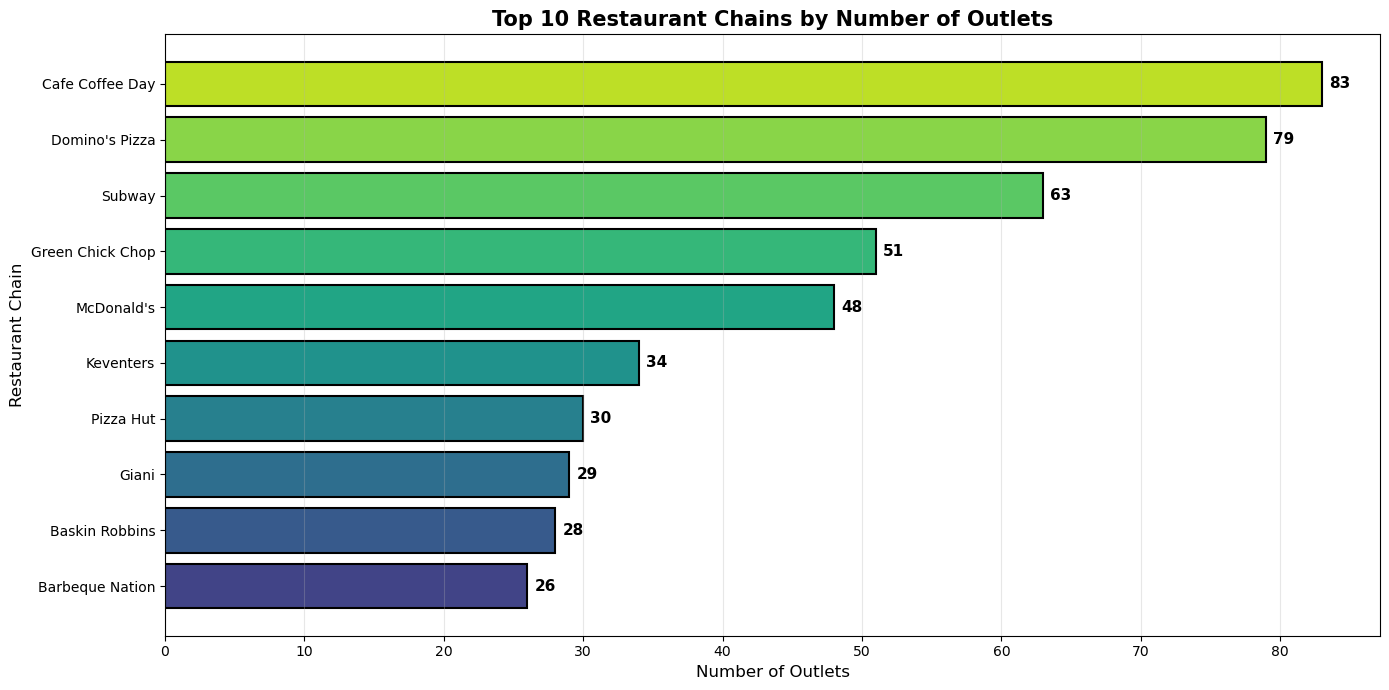

In [5]:
# Top 10 chains by outlets
top_10_chains = chain_stats.head(10)

plt.figure(figsize=(14, 7))
colors = plt.cm.viridis(np.linspace(0.2, 0.9, 10))

bars = plt.barh(top_10_chains['Restaurant Name'][::-1], 
                top_10_chains['outlets'][::-1],
                color=colors, edgecolor='black', linewidth=1.5)

# Labels
for bar, count in zip(bars, top_10_chains['outlets'][::-1]):
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
             f'{int(width)}', va='center', fontsize=11, fontweight='bold')

plt.title('Top 10 Restaurant Chains by Number of Outlets', fontsize=15, fontweight='bold')
plt.xlabel('Number of Outlets', fontsize=12)
plt.ylabel('Restaurant Chain', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

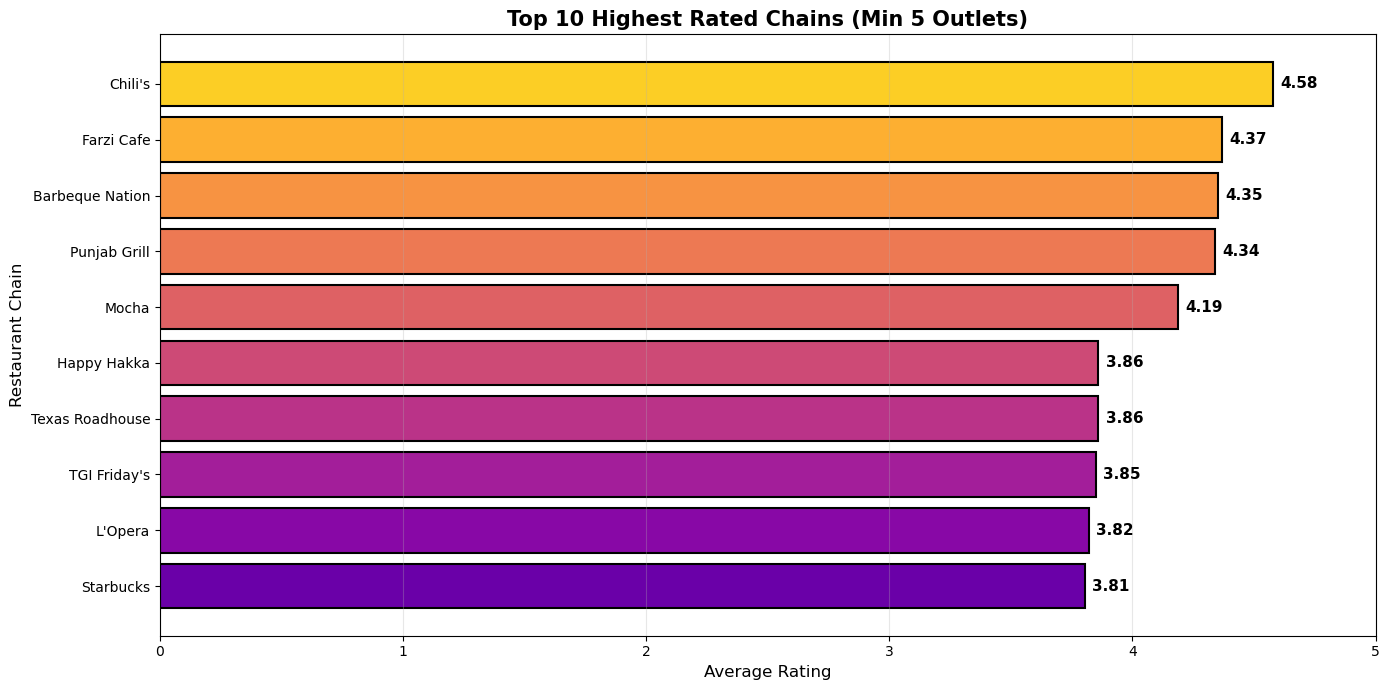

In [6]:
# Filter chains with 5+ outlets for fair rating comparison
popular_chains = chain_stats[chain_stats['outlets'] >= 5].copy()
popular_chains = popular_chains.sort_values('avg_rating', ascending=False).head(10)

plt.figure(figsize=(14, 7))
colors = plt.cm.plasma(np.linspace(0.2, 0.9, 10))

bars = plt.barh(popular_chains['Restaurant Name'][::-1],
                popular_chains['avg_rating'][::-1],
                color=colors, edgecolor='black', linewidth=1.5)

# Labels
for bar, rating in zip(bars, popular_chains['avg_rating'][::-1]):
    width = bar.get_width()
    plt.text(width + 0.03, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}', va='center', fontsize=11, fontweight='bold')

plt.title('Top 10 Highest Rated Chains (Min 5 Outlets)', fontsize=15, fontweight='bold')
plt.xlabel('Average Rating', fontsize=12)
plt.ylabel('Restaurant Chain', fontsize=12)
plt.xlim(0, 5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

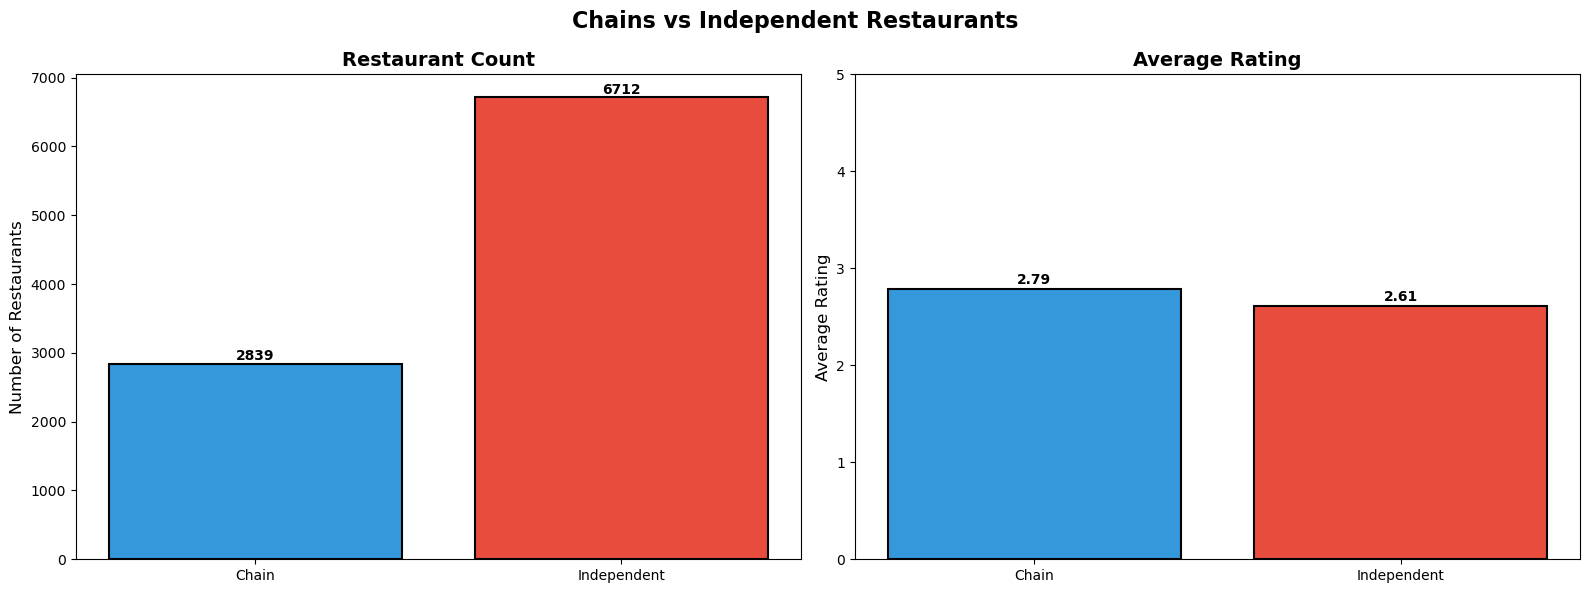

In [7]:
# Bar chart comparing chain vs independent
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Count comparison
counts = comparison['count']
axes[0].bar(counts.index, counts.values, 
            color=['#3498DB', '#E74C3C'], edgecolor='black', linewidth=1.5)
axes[0].set_title('Restaurant Count', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Restaurants', fontsize=12)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

# Chart 2: Rating comparison
ratings = comparison['avg_rating']
axes[1].bar(ratings.index, ratings.values,
            color=['#3498DB', '#E74C3C'], edgecolor='black', linewidth=1.5)
axes[1].set_title('Average Rating', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average Rating', fontsize=12)
axes[1].set_ylim(0, 5)
for i, v in enumerate(ratings.values):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')

plt.suptitle('Chains vs Independent Restaurants', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

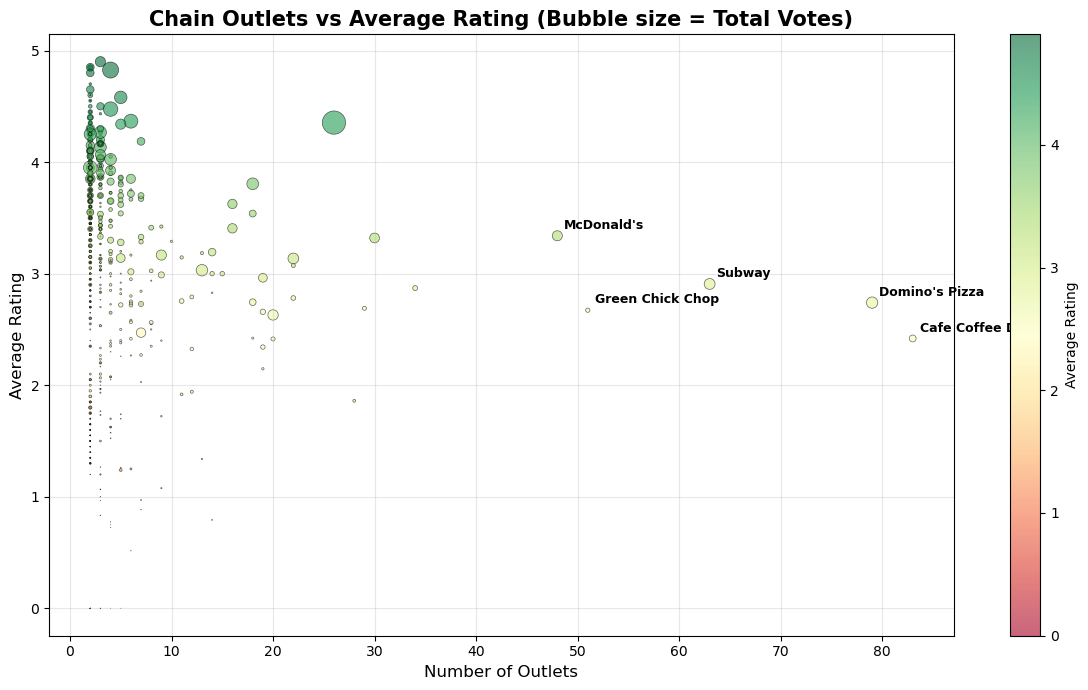

In [8]:
# Scatter plot: Outlets vs Average Rating
plt.figure(figsize=(12, 7))

plt.scatter(chain_stats['outlets'], chain_stats['avg_rating'],
            s=chain_stats['total_votes']/100,
            c=chain_stats['avg_rating'],
            cmap='RdYlGn',
            alpha=0.6,
            edgecolors='black',
            linewidth=0.5)

# Annotate top chains
top_5 = chain_stats.nlargest(5, 'outlets')
for _, row in top_5.iterrows():
    plt.annotate(row['Restaurant Name'], 
                 (row['outlets'], row['avg_rating']),
                 fontsize=9, fontweight='bold',
                 xytext=(5, 5), textcoords='offset points')

plt.colorbar(label='Average Rating')
plt.title('Chain Outlets vs Average Rating (Bubble size = Total Votes)', 
          fontsize=15, fontweight='bold')
plt.xlabel('Number of Outlets', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 🔍 Insights

### 1. Chain Presence
- Total potential chains identified: **{X}**
- Total outlets across chains: **{Y}**
- Percentage of restaurants that are part of chains: **{Z}%**

### 2. Top Chains by Outlets
- **#1:** {chain name} with {count} outlets
- **#2:** {chain name} with {count} outlets
- **#3:** {chain name} with {count} outlets

### 3. Rating Comparison
- **Chain restaurants** average rating: **{rating}**
- **Independent restaurants** average rating: **{rating}**
- Difference: **{+/- X}**

### 4. Votes & Popularity
- Chain restaurants get more votes on average: **{avg}** vs **{avg}**
- Top voted chain: **{name}** with **{votes}** votes

### Conclusion
- Restaurant chains have a **significant presence** in the dataset
- **{Chains/Independents}** tend to have higher ratings
- Chains benefit from **brand recognition and customer trust**
- Popular chains have **higher customer engagement** (votes)